### TAREA OPCIONAL ECUACIONES NO LINEALES
**Tarea elaborada en grupo. Integrantes: Sofía Salinas Rico, William Gallego Molano y Sara Rivera Sanabria**

# Problema (Kelley)

Considere el método de Shamanskii de orden $m$ definido de la siguiente manera.

Dado $x_n$, calcule $x_{n+1}$ usando $m$ pasos del método de la cuerda, esto es,

$$
z_1 = x_n - \frac{f(x_n)}{f'(x_n)}
$$

$$
z_{j+1} = z_j - \frac{f(z_j)}{f'(x_n)},
\qquad 1 \leq j \leq m-1,
$$

$$
x_{n+1} = z_m.
$$

Observe que se avanza $m$ pasos sin actualizar la derivada en el punto.

Implemente el método para un orden $m$ definido por el usuario y verifique su código con una ecuación escalar. Para la ecuación usada, ¿como depende el tiempo de computo de $m$?



In [1]:
# Implementación del método de Shamanskii de orden m

function shamanskii(f, fp, x0, m; tol=1e-15, maxiter=100)
    @assert m >= 1 "El orden m debe ser >= 1"
    x = float(x0)
    hist = [x]

    for n in 1:maxiter
        fx  = f(x)
        fpx = fp(x)          # Se evalúa SOLO una vez por iteración externa

        # Paso 1: Newton completo
        z = x - fx / fpx

        # Pasos 2..m: cuerda (se reutiliza la misma derivada f'(xₙ))
        for j in 2:m
            z = z - f(z) / fpx
        end

        push!(hist, z)

        if abs(z - x) < tol
            x = z
            break
        end
        x = z
    end

    return (raíz=x, iteraciones=length(hist)-1, residuo=f(x), historial=hist)
end

shamanskii (generic function with 1 method)

In [2]:
# Verificación con f(x) = x² - 2 para hallar √2

f_sqrt(x) = x^2 - 2
fp_sqrt(x) = 2x

println("Buscando √2 = 1.4142135623730951...")
println()

# Probar diferentes órdenes m
for m in 1:5
    res = shamanskii(f_sqrt, fp_sqrt, 1.0, m)
    println("m = $m:")
    println("  raíz       = ", res.raíz)
    println("  iteraciones = ", res.iteraciones)
    println("  residuo     = ", res.residuo)
    println("  error vs √2 = ", abs(res.raíz - sqrt(2)))
    println()
end

Buscando √2 = 1.4142135623730951...

m = 1:
  raíz       = 1.414213562373095
  iteraciones = 6
  residuo     = -4.440892098500626e-16
  error vs √2 = 2.220446049250313e-16

m = 2:
  raíz       = 1.414213562373095
  iteraciones = 4
  residuo     = -4.440892098500626e-16
  error vs √2 = 2.220446049250313e-16

m = 3:
  raíz       = 1.414213562373095
  iteraciones = 4
  residuo     = -4.440892098500626e-16
  error vs √2 = 2.220446049250313e-16

m = 4:
  raíz       = 1.414213562373095
  iteraciones = 4
  residuo     = -4.440892098500626e-16
  error vs √2 = 2.220446049250313e-16

m = 5:
  raíz       = 1.4142135623730951
  iteraciones = 3
  residuo     = 4.440892098500626e-16
  error vs √2 = 0.0



In [20]:
# Verificación con f(x) = cos(x) - x (punto fijo del coseno)

f_cos(x) = cos(x) - x
fp_cos(x) = -sin(x) - 1

println("Buscando punto fijo de cos(x) ≈ 0.7390851332151607...")
println()

# Probar diferentes órdenes m
for m in 1:5
    res = shamanskii(f_cos, fp_cos, 1.0, m)
    println("m = $m:")
    println("  raíz       = ", res.raíz)
    println("  iteraciones = ", res.iteraciones)
    println("  residuo     = ", res.residuo)
    println()
end

Buscando punto fijo de cos(x) ≈ 0.7390851332151607...

m = 1:
  raíz       = 0.7390851332151607
  iteraciones = 5
  residuo     = 0.0

m = 2:
  raíz       = 0.7390851332151607
  iteraciones = 4
  residuo     = 0.0

m = 3:
  raíz       = 0.7390851332151607
  iteraciones = 3
  residuo     = 0.0

m = 4:
  raíz       = 0.7390851332151607
  iteraciones = 3
  residuo     = 0.0

m = 5:
  raíz       = 0.7390851332151607
  iteraciones = 3
  residuo     = 0.0



In [21]:
# Verificación con f(x) = (x-2)³ (raíz triple en x=2)
# Nota: con raíces múltiples, la convergencia se degrada a lineal

f_mult(x) = (x - 2)^3
fp_mult(x) = 3(x - 2)^2

println("Buscando raíz triple x = 2 de f(x) = (x-2)³...")
println()

# Probar diferentes órdenes m
for m in 1:5
    res = shamanskii(f_mult, fp_mult, 3.0, m)
    println("m = $m:")
    println("  raíz       = ", res.raíz)
    println("  iteraciones = ", res.iteraciones)
    println("  residuo     = ", res.residuo)
    println("  error vs 2  = ", abs(res.raíz - 2.0))
    println()
end

Buscando raíz triple x = 2 de f(x) = (x-2)³...

m = 1:
  raíz       = 2.0000000000000013
  iteraciones = 84
  residuo     = 2.3646911585481288e-45
  error vs 2  = 1.3322676295501878e-15

m = 2:
  raíz       = 2.000000000000001
  iteraciones = 61
  residuo     = 7.006492321624085e-46
  error vs 2  = 8.881784197001252e-16

m = 3:
  raíz       = 2.000000000000001
  iteraciones = 51
  residuo     = 7.006492321624085e-46
  error vs 2  = 8.881784197001252e-16

m = 4:
  raíz       = 2.0000000000000013
  iteraciones = 45
  residuo     = 2.3646911585481288e-45
  error vs 2  = 1.3322676295501878e-15

m = 5:
  raíz       = 2.0000000000000013
  iteraciones = 41
  residuo     = 2.3646911585481288e-45
  error vs 2  = 1.3322676295501878e-15



## Análisis: ¿Cómo depende el tiempo de cómputo de $m$?

Para cada ecuación, medimos el tiempo de ejecución y contamos las iteraciones externas para diferentes valores de $m$.

In [23]:
using Printf

# Función para medir tiempo sin dependencias externas
function medir_tiempo(f, args...; repeticiones=5)
    f(args...)  # warm-up
    t0 = time_ns()
    for _ in 1:repeticiones
        f(args...)
    end
    t1 = time_ns()
    return (t1 - t0) / repeticiones / 1e9  # segundos
end

# Definir las tres ecuaciones
ecuaciones = [
    ("√2", f_sqrt, fp_sqrt, 1.0, sqrt(2)),
    ("cos(x)", f_cos, fp_cos, 1.0, 0.7390851332151607),
    ("raíz triple", f_mult, fp_mult, 3.0, 2.0)
]

println("="^80)
println("ANÁLISIS: TIEMPO DE CÓMPUTO vs ORDEN m")
println("="^80)

for (nombre, f, fp, x0, raiz_exacta) in ecuaciones
    println()
    println("Ecuación: ", nombre)
    println("-"^80)
    println("  m  | tiempo (μs) | iter. ext. | eval f | eval f' | error")
    println("-----|-------------|------------|--------|---------|--------")
    
    for m in 1:10
        # Medir tiempo
        t = medir_tiempo(shamanskii, f, fp, x0, m; repeticiones=10)
        
        # Obtener resultado
        res = shamanskii(f, fp, x0, m)
        N_ext = res.iteraciones
        eval_f = N_ext * m      # m evaluaciones de f por iteración externa
        eval_fp = N_ext         # 1 evaluación de f' por iteración externa
        error = abs(res.raíz - raiz_exacta)
        
        @printf("%3d | %9.1f | %10d | %6d | %7d | %.2e\n", 
                m, t*1e6, N_ext, eval_f, eval_fp, error)
    end
end

ANÁLISIS: TIEMPO DE CÓMPUTO vs ORDEN m

Ecuación: √2
--------------------------------------------------------------------------------
  m  | tiempo (μs) | iter. ext. | eval f | eval f' | error
-----|-------------|------------|--------|---------|--------
  1 |       0.6 |          6 |      6 |       6 | 2.22e-16
  2 |       0.4 |          4 |      8 |       4 | 2.22e-16
  3 |       0.6 |          4 |     12 |       4 | 2.22e-16
  4 |       0.5 |          4 |     16 |       4 | 2.22e-16
  5 |       0.4 |          3 |     15 |       3 | 0.00e+00
  6 |       0.4 |          3 |     18 |       3 | 2.22e-16
  7 |       0.5 |          3 |     21 |       3 | 2.22e-16
  8 |       0.5 |          3 |     24 |       3 | 0.00e+00
  9 |       0.4 |          3 |     27 |       3 | 0.00e+00
 10 |       0.5 |          3 |     30 |       3 | 2.22e-16

Ecuación: cos(x)
--------------------------------------------------------------------------------
  m  | tiempo (μs) | iter. ext. | eval f | eval f' | erro

Asi pues, podemos concluir que el tiempo de computo depende en general del tiempo de iteraciones externas y que esta cantidad depende a su vez de $m$.
dicho de otra manera, con un m pequeño se hacer pocas evaluaciones por iteracion, pero se hace mas iteraciones, mientras que con un m grande se hacen muchas evaluaciones or iteracion, pero se hacen pocas iteraciones.

# Problema (Quarteroni, Saleri, Gervasio)

Considere un plano cuya pendiente varía con tasa constante $\omega$ y un punto de masa quieto en el tiempo $t = 0$.

En el tiempo $t > 0$ su posición es dada por

$$
s(t,\omega) =
\frac{g}{2\omega^2}
\left[
\sinh(\omega t) - \sin(\omega t)
\right]
$$

donde $g = 9.8 \, \frac{m}{s^2}$.

Suponga que el objeto se ha movido $1$ metro en un segundo, calcule el valor correspondiente de $\omega$ con 12 decimales exactos.


## Solución: cálculo de $\omega$ (Quarteroni, Saleri, Gervasio)

Queremos hallar $\omega$ tal que $s(1,\omega)=1$, es decir, una raíz de

$$
f(\omega)=\frac{g}{2\omega^2}\Big[\sinh(\omega)-\sin(\omega)\Big]-1=0,\qquad g=9.8 .
$$

**Existencia y ubicación.** Como $\sinh(\omega)-\sin(\omega)\approx \tfrac{\omega^3}{3}$ cuando $\omega\to0^+$, se tiene $f(\omega)\to -1$ si $\omega\to 0^+$, y $f(\omega)\to+\infty$ si $\omega\to\infty$. Además $f(0.5)<0$ y $f(1)>0$, así que por el teorema del valor intermedio hay una raíz en $[0.5,1]$.

Calcularemos la raíz con tres métodos: bisección, Newton y la función fzero de Roots.

In [ ]:
using Plots

In [ ]:
#funcion de posicion
pos_masa(t, ω; g=9.8) = g/(2*ω^2) * (sinh(ω*t) - sin(ω*t))

pos_masa (generic function with 1 method)

In [ ]:
#función objetivo y su derivada
begin
	# f(ω) = s(1, ω) - 1
	f_omega(ω) = pos_masa(1.0, ω) - 1.0

	# f'(ω) = (g/2) * [ (cosh ω - cos ω)/ω² - 2 (sinh ω - sin ω)/ω³ ]
	fp_omega(ω) = 9.8/2 * ( (cosh(ω) - cos(ω))/ω^2 - 2*(sinh(ω) - sin(ω))/ω^3 )
end

fp_omega (generic function with 1 method)

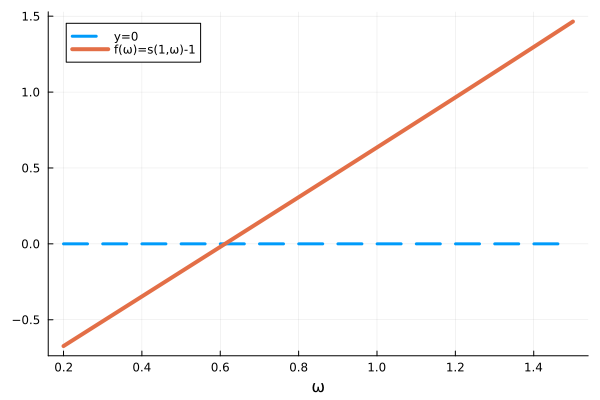

In [ ]:
#gráfica
let
	ω = 0.2:0.001:1.5
	plot(ω, 0 .* ω, ls=:dash, lw=3, label="y=0")
	plot!(ω, f_omega.(ω), lw=4, label="f(ω)=s(1,ω)-1", xlabel="ω")
end

Aca confirmamos que una raiz deberia estar entre 0.5 y 0.7

In [ ]:
# bisección en [0.5, 1]
# Se detiene cuando |e| < 1e-15 (longitud del intervalo) o |f(c)| < 1e-15.

bis_omega = let
	a, b, M, delb, epsb = 0.5, 1.0, 200, 1e-15, 1e-15
	u = f_omega(a)
	v = f_omega(b)
	e = b - a
	k = 1
	c = a + e
	w = f_omega(c)
	if sign(u) != sign(v)
		while k <= M && abs(e) > delb && abs(w) > epsb
			e = e/2
			if sign(w) != sign(u)
				b = c
				v = w
			else
				a = c
				u = w
			end
			k = k + 1
			c = a + e
			w = f_omega(c)
		end
	end
	(ω=c, iteraciones=k, residuo=w, long_intervalo=abs(e))
end

(ω = 0.6121425707030941, iteraciones = 49, residuo = 4.440892098500626e-16, long_intervalo = 1.7763568394002505e-15)

In [ ]:
# Newton desde ω₀ = 1
newton_omega = let
	x = 1.0
	hist = [x]
	for n in 1:20
		xn = x - f_omega(x)/fp_omega(x)
		push!(hist, xn)
		if abs(xn - x) < 1e-15
			x = xn
			break
		end
		x = xn
	end
	(ω=x, iteraciones=length(hist)-1, residuo=f_omega(x), historial=hist)
end

(ω = 0.6121425707030939, iteraciones = 4, residuo = -2.220446049250313e-16, historial = [1.0, 0.6133562454514907, 0.6121425747383072, 0.6121425707030941, 0.6121425707030939])

In [ ]:
using Roots

In [ ]:
#comparacion con Roots.fzero
fzero_omega = fzero(f_omega, 0.5, 1.0)

0.6121425707030939

In [ ]:
#resultado final con 12 decimales
let
	ω = bis_omega.ω
	println("Biseccion : ω = ", round(bis_omega.ω; digits=12))
	println("Newton    : ω = ", round(newton_omega.ω; digits=12))
	println("fzero     : ω = ", round(fzero_omega; digits=12))
	println()
	println("Verificación: s(1, ω) = ", pos_masa(1.0, ω))
end

Bisección : ω = 0.612142570703
Newton    : ω = 0.612142570703
fzero     : ω = 0.612142570703

Verificación: s(1, ω) = 1.0000000000000004


**Resultado.**

$${\omega \approx 0.612142570703}
$$

Los tres métodos coinciden. Observe que Newton necesita solo 4 iteraciones frente a 50 de la bisección.